# 05 – Des intrants FAOSTAT réels améliorent-ils le modèle ?

**Question.** Le modèle servi utilise la culture, la température, la pluie et le total national de pesticides. Des **intrants mesurés** par pays et par année (azote, phosphate et potasse en kg/ha de terres cultivées, part des terres équipées pour l'irrigation, pesticides en kg/ha) amélioreraient-ils la prédiction ?

**Source.** Exports FAOSTAT d'octobre 2026, raccordés au dataset consolidé par `python -m agritech_crop_reco.data.faostat` (`data/processed/faostat_inputs.csv`).

**Protocole** (identique à l'étape 2, script `python -m agritech_crop_reco.modeling.experiment_inputs`, expérience MLflow `agritech-crop-yield-03-intrants-faostat`) :
- jeu d'entraînement seulement, validation croisée par pays ; **les 21 pays de test ne sont pas utilisés** ;
- même modèle et **mêmes hyperparamètres** que le modèle servi : seules les variables changent ;
- **règle fixée avant l'exécution** : une configuration n'est retenue que si son RMSE bat la référence de plus d'**un écart-type** de la référence.

Ce notebook relit les résultats du script (il ne relance pas l'expérience, pour ne pas dupliquer les runs MLflow).

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from agritech_crop_reco.config import PROJECT_ROOT, load_settings
from agritech_crop_reco.data.faostat import INPUT_COLS, INPUTS_FILE, add_inputs
from agritech_crop_reco.modeling.train import load_train_test

settings = load_settings()
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.float_format", "{:,.3f}".format)
FIG = PROJECT_ROOT / "reports" / "figures"

inputs = pd.read_csv(settings.processed_dir / INPUTS_FILE)
train, _, _ = load_train_test(settings)
train = add_inputs(train, inputs)
NAMES = {
    "n_kg_ha": "Azote (kg/ha)",
    "p_kg_ha": "Phosphate (kg/ha)",
    "k_kg_ha": "Potasse (kg/ha)",
    "irrig_share": "Part irriguée (%)",
    "pest_kg_ha": "Pesticides (kg/ha)",
}
pd.DataFrame(
    {
        "couverture (lignes d'entraînement)": train[INPUT_COLS].notna().mean(),
        "médiane": train[INPUT_COLS].median(),
    }
).rename(index=NAMES)

,couverture (lignes d'entraînement),médiane
Azote (kg/ha),0.995,29.770
Phosphate (kg/ha),0.993,12.180
Potasse (kg/ha),0.992,4.480
Part irriguée (%),0.985,9.500
Pesticides (kg/ha),1.000,0.950


**Lecture.** Les intrants couvrent 98 à 100 % des observations. Trois pays ont changé de nom dans FAOSTAT et ont été raccordés explicitement (`Türkiye`, `Netherlands (Kingdom of the)`, `United Kingdom of Great Britain and Northern Ireland`) ; sans cette correction, ils restaient sans intrants et le gain mesuré était sous-estimé.

## 1. Les intrants mesurent-ils des choses différentes ?

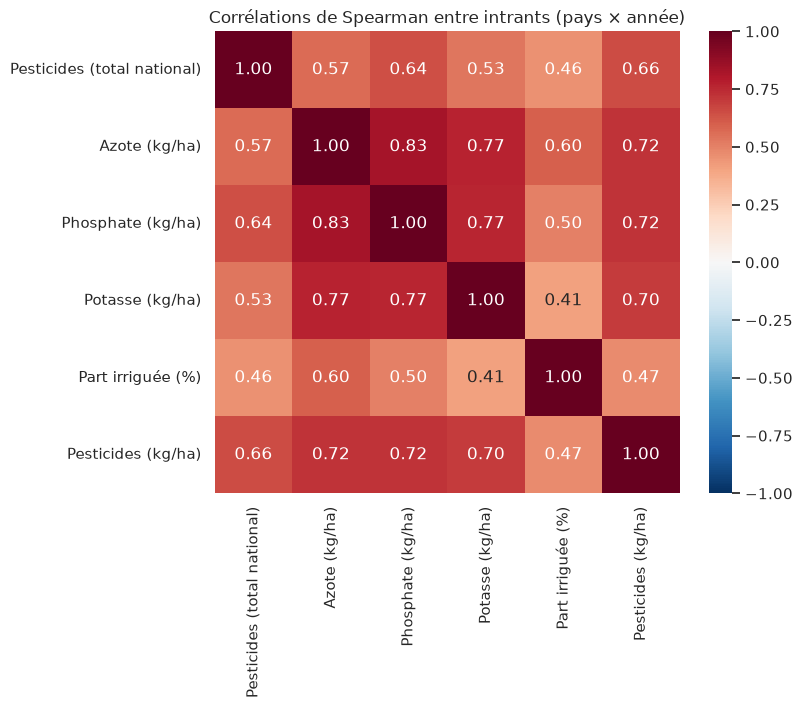

In [2]:
corr = train[["pesticides_tonnes", *INPUT_COLS]].corr("spearman").rename(index=NAMES, columns=NAMES)
corr = corr.rename(
    index={"pesticides_tonnes": "Pesticides (total national)"},
    columns={"pesticides_tonnes": "Pesticides (total national)"},
)
fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Corrélations de Spearman entre intrants (pays × année)")
fig.savefig(FIG / "05_intrants_correlations.png", dpi=120, bbox_inches="tight")
plt.show()

**Lecture.** Azote, phosphate, irrigation et pesticides sont **corrélés entre eux** : à l'échelle d'un pays, ils mesurent en grande partie un même phénomène, le **niveau d'intensification** de l'agriculture. C'est pourquoi ces données nationales ne permettent pas d'isoler l'effet propre de l'engrais ou de l'irrigation (qui reste mesuré, à la parcelle, sur le jeu simulé).

## 2. Résultats et décision

,label,cv_rmse_mean,cv_rmse_std,cv_r2_mean,cv_ranking_spearman_mean,threshold,retained
reference,"Référence (modèle servi : température, pluie, ...",4.967,0.441,0.589,0.843,4.525,False
avec_intrants,"+ intrants FAOSTAT (N, P, K, part irriguée, pe...",4.705,0.357,0.630,0.835,4.525,False
intrants_sans_pesticides_totaux,Intrants FAOSTAT à la place des pesticides totaux,4.764,0.357,0.621,0.835,4.525,False


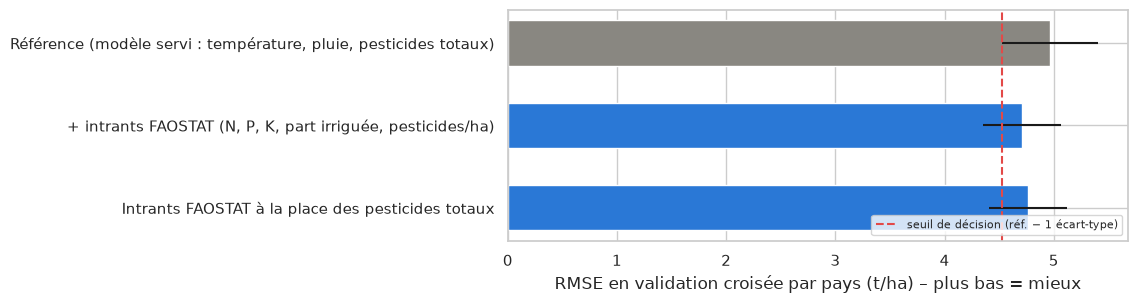

In [3]:
res = pd.read_csv(PROJECT_ROOT / "reports" / "inputs_experiment.csv", index_col=0)
cols = [
    "label",
    "cv_rmse_mean",
    "cv_rmse_std",
    "cv_r2_mean",
    "cv_ranking_spearman_mean",
    "threshold",
    "retained",
]
display(res[cols])

fig, ax = plt.subplots(figsize=(8, 3))
colors = ["#898781" if i == "reference" else "#2a78d6" for i in res.index]
ax.barh(res["label"], res["cv_rmse_mean"], xerr=res["cv_rmse_std"], color=colors, height=0.55)
ax.axvline(
    res["threshold"].iloc[0],
    color="#e34948",
    ls="--",
    label="seuil de décision (réf. − 1 écart-type)",
)
ax.set_xlabel("RMSE en validation croisée par pays (t/ha) – plus bas = mieux")
ax.invert_yaxis()
ax.legend(loc="lower right", fontsize=8)
fig.savefig(FIG / "05_intrants_decision.png", dpi=120, bbox_inches="tight")
plt.show()

In [4]:
imp = pd.read_csv(PROJECT_ROOT / "reports" / "inputs_experiment_importance.csv", index_col=0)
imp.rename(
    index={
        **NAMES,
        "crop": "Culture",
        "avg_temp_c": "Température",
        "rainfall_mm": "Pluie",
        "pesticides_tonnes": "Pesticides (total national)",
    }
)

,mean,std
Culture,4.516,0.434
Température,0.294,0.155
Pesticides (kg/ha),0.263,0.183
Phosphate (kg/ha),0.204,0.130
Pesticides (total national),0.197,0.157
Part irriguée (%),0.126,0.044
Azote (kg/ha),0.091,0.070
Potasse (kg/ha),0.017,0.025
Pluie,0.010,0.099


## 3. Conclusion

- **Gain réel mais modeste** : avec les intrants, le RMSE passe de ≈ 4,97 à ≈ 4,71 t/ha (−5 %), le R² de ≈ 0,59 à ≈ 0,63, et les résultats sont plus stables d'un pli à l'autre.
- **Sous le seuil fixé à l'avance** (≈ 4,53) : la configuration **n'est pas retenue**. La règle n'est pas modifiée après coup. Le classement des cultures (métrique métier) n'est d'ailleurs pas amélioré (≈ 0,835 contre ≈ 0,843).
- **Interprétation** : la part irriguée a un poids stable mais faible ; l'azote, le phosphate et les pesticides par hectare se partagent un même signal d'intensification. Ces données **nationales** améliorent un peu la prédiction, mais ne mesurent pas l'effet d'une pratique **sur une parcelle**.
- **Piste** : c'est la première amélioration à retester, avec des hyperparamètres optimisés pour ces variables et des données plus récentes (FAOSTAT couvre jusqu'en 2024 ; il faudrait alors des données climatiques au-delà de 2013).